# Fundamentos de Computación Cuántica

Desarrollado por Alejandro Contreras Reynoso.

Instructor: Adrian Ortega.

CUGDL,  Octubre 2026

# 2 — Hola mundo en Qiskit

Este notebook es una introducción a Qiskit. Que es la biblioteca para computación cuántica que se utilizará a lo largo del curso. 

El notebook está hecho para Qiskit 2.x.

Primero carguemos la biblioteca y las funciones que se van a utilizar:

In [38]:
#%pip install pylatexenc matplotlib

In [3]:
import numpy as np                                      # arreglos y operaciones numéricas
from qiskit import QuantumCircuit                       # construye el circuito, qubits, compuertas y mediciones
from qiskit.quantum_info import Operator, Statevector   # Operator, la matriz del circuito. Statevector, el estado que produce
from qiskit.visualization import plot_histogram, plot_bloch_multivector   # histograma de resultados y esfera de Bloch
from qiskit.result import ProbDistribution              # convierte cantidad de mediciones en probabilidades (que suman 1)
from IPython.display import display   # para mostrar varias figuras en una misma celda

print("qiskit listo")

qiskit listo


## 1. Tu primer circuito

Un circuito cuántico se construye en tres pasos: se declara con cuántos qubits se necesitan, se aplican compuertas y se hacen mediciones.
Además se pueden hacer distintas gráficas para ir checando paso a paso el proceso.

El comando`QuantumCircuit(1)` crea un "circuito" de un qubit en python, que se inicializa siempre en el estado
$|0\rangle$. El método `.h(0)` aplica la compuerta de Hadamard al qubit número 0.

Un diagrama de un circuito cuántico se lee de izquierda a derecha, como una línea de tiempo. La línea
horizontal es el qubit y cada caja es una compuerta que actúa sobre él.

En este primer ejemplo se inicializa un circuito de un qubit, se le aplica una compuerta Hadamard y finalmente se lo dibuja:

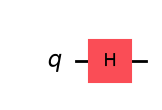

In [24]:
qc = QuantumCircuit(1)
qc.h(0)

qc.draw("mpl")

### Ejercicio 1

Construye un circuito de un qubit que aplique la compuerta `X` en lugar de `H` y dibújalo.
La compuerta X es un NOT cuántico. La compuerta `X` se añade a un circuito como `qc.x(j)`, donde `j` representa el qubit al que se le va a aplicar la compuerta, en este caso `j=0`.

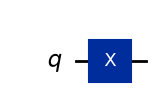

In [25]:
#Respuesta
qc = QuantumCircuit(1)
qc.x(0)

qc.draw("mpl")

<details>
<summary>Ver respuesta</summary>

```python
qc_x = QuantumCircuit(1)
qc_x.x(0)

qc_x.draw("mpl")
```

El dibujo es igual al anterior pero con una `X` dentro de la caja. Cada compuerta
tiene su método con el nombre en minúscula: `.x()`, `.y()`, `.z()`, `.h()`.

</details>

La librería de todas las compuertas disponibles en qiskit puede consultarse en: https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_library

## 2. Las compuertas son una matriz

Aplicar compuertas a un circuito es multiplicar un vector columna por una matriz. Entonces todas las compuertas que se aplican 
un circuito se pueden ver como una sola matriz que se aplica sobre el vector de estado, independientemente del número de qubits. 


Qiskit calcula toda la operación que se aplica sobre el circuito con `Operator(qc).data`, que devuelve un arreglo de numpy.

Por ejemplo:

In [26]:
U = Operator(qc).data 
print(U)

[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]


Esta es la compuerta de Hadamard escrita como matriz:

$$H = \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$$

Todas las compuertas que se aplican sobre un circuito son matrices unitarias. Por definición, si $U$ es una matriz unitaria, entonces se cumple que 
$$
UU^\dagger = U^\dagger U = \textbf{1},
$$
dónde $U^\dagger = (U^T)^*$. Es decir, el super-indice $\dagger$ en una matriz indica que debemos de calcular su matriz transpuesta (representada por $T$) y luego la conjugación de cada entrada de números (complejos) que conforman la $U$. La conjugación compleja de un número complejo consiste en que, si $z=x+iy$, entonces $z^* = x - iy$. Esto es, la parte imaginaria de $z$ cambia de signo bajo la regla $i^* = -i$. Además, $\textbf{1}$ representa a la matriz unitaria (matriz cuadrada con entradas ceros excepto en la diagonal donde las entradas todas son iguales a $1$).

Si por ejemplo $U = \begin{pmatrix}u_{11} & u_{12}\\ u_{21} & u_{22} \end{pmatrix}$, donde todo $u_{ij}$ es un número complejo que podemos escribir como $u_{ij} = x_{ij} + i y_{ij}$, entonces la operación traspuesta es
$$
U^T = \begin{pmatrix}u_{11} & u_{21} \\ u_{12} & u_{22} \end{pmatrix},
$$
y si luego conjungamos esta matriz tendremos
$$
U^\dagger = (U^T)^* = \begin{pmatrix} u_{11} & u_{21} \\ u_{12} & u_{22}\end{pmatrix}^* = \begin{pmatrix} u_{11}^* & u_{21}^* \\ u_{12}^* & u_{22}^*\end{pmatrix}.
$$

Para el caso específico de la matriz de Hadamard $H$, tenemos que todas las entradas son números reales (esto es, la parte imaginaria es cero), por lo que conjugar un número real devuelve el mismo número real. Es decir, si $z = x + i0$, entonces $z^* = x - i*0 = x$.
Así, 
$$
H H^\dagger = H H^T= \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} = \frac{1}{2}\begin{pmatrix}1+1 & 1-1 \\ 1-1 & 1+1 \end{pmatrix} = \begin{pmatrix}1 & 0\\ 0 & 1 \end{pmatrix} = \mathbf{1},
$$
dónde notamos que también en el caso específico de $H$, $H^T = H$ (intercambiar filas y columnas con la transpuesta devuelve la misma matriz original $H$). De un cálculo similar podemos ver que $H^\dagger H = \mathbf{1}$.

__¿Por qué es importante que todas las compuertas en computación cuántica sean matrices?__ La explicación requiere un poco de cálculo, pero el resultado es que básicamente, como se mencionó en la presentación de esta clase, la medición de un qubit siempre es un proceso aleatorio que devuelve 0 ó 1 con cierta probabilidad. El hecho de que una matriz sea unitaria garantiza que la probabilidad total seguirá siendo igual a 1 (aunque las probabilidades relativas de medir 0 ó 1 cambien).

### Ejercicio 2

Obtén la matriz del circuito con la compuerta `X` que construiste en el ejercicio 1.
¿Qué matriz esperabas, sabiendo que X intercambia $|0\rangle$ y $|1\rangle$?

In [27]:
#Respuesta
qc = QuantumCircuit(1)
qc.x(0)
U = Operator(qc).data
print(f"matriz:{U} ")


matriz:[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]] 


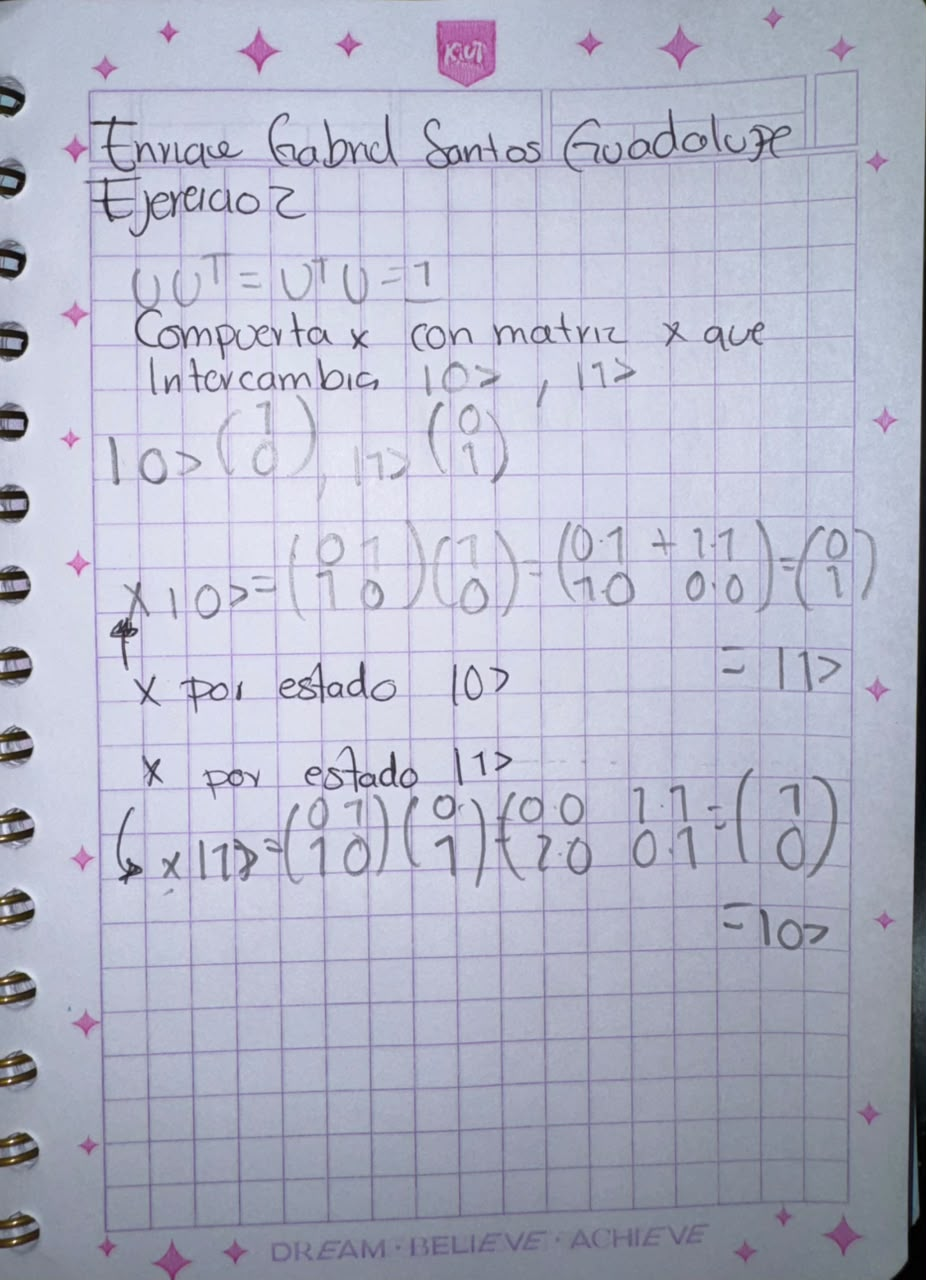

In [40]:
from IPython.display import Image
Image("eje2.png")

<details>
<summary>Ver respuesta</summary>

```python
Ux = Operator(qc_x).data
print(Ux)
```

Es la matriz

$$X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}$$

que es justo la que intercambia $|0 \rangle$ por $|1 \rangle$.

</details>

## 3. El estado que produce el circuito

La matriz unitaria total describe la acción del circuito. Falta conocer el estado final de los qubits

Un qubit siempre se inicializa en el estado $|0\rangle$, mientras que un estado general es de la forma

$$|\psi\rangle = \alpha\,|0\rangle + \beta\,|1\rangle ,$$

donde $\alpha$ y $\beta$ son números complejos que se los conoce como amplitudes de probabilidad. Estos números _no son
probabilidades_. Las probabilidades se obtienen elevando su módulo al cuadrado,
$|\alpha|^2$ es la probabilidad de medir $|0 \rangle$ y $|\beta|^2$ la de medir $|1 \rangle$. Además, como ya se dijo en la presentación, $|\alpha|^2 + |\beta|^2 = 1$.

La función`Statevector(qc)` corre el circuito y devuelve el estado resultante.

In [32]:
estado = Statevector(qc)

print(f"amplitudes:{estado.data}")
print(f"Priob: {estado.probabilities()} ")

amplitudes:[0.+0.j 1.+0.j]
Priob: [0. 1.] 


Se puede escribir en latex usando: 

In [33]:
estado.draw("latex")

<IPython.core.display.Latex object>

Las dos amplitudes valen $1/\sqrt{2} \approx 0.707$. Al elevarlas al cuadrado dan
$0.5$ cada una y por eso las probabilidades son 0.5.

El qubit no está en $|0\rangle$ ó $|1\rangle$, sino em ambos estados a mismo tiempo. A esto se le llama _superposición_.
Está en una combinación de ambos y sólo al medirlo se obtiene uno de los dos.


### Ejercicio 3

Obtén el estado final del circuito con la compuerta `X` del ejercicio 1. Obsera sus
amplitudes y sus probabilidades. ¿Hay superposición?

In [22]:
#Respuesta
qc = QuantumCircuit(1)
qc.x(0)
estado_x = Statevector(qc)

print(f"amplitudes:{estado_x.data}")
print(f"Priob:{estado_x.probabilities()}")





amplitudes:[0.+0.j 1.+0.j]
Priob:[0. 1.]


In [23]:
estado_x.draw("latex")

<IPython.core.display.Latex object>

# **Respuesta a la pregunta del ejercicio 3**

No existe superposicion ya que uno da 0 y otro da 1 para que exista ambos tendrian que dar 0 o alguna forma en la que su suma sea igual a 1, en otras palabras no convergen en el mismo estado , sino que uno converge en el qubit 0 y el otro en el qubit 1.

<details>
<summary>Ver respuesta</summary>

```python
estado_x = Statevector(qc_x)

print("amplitudes   :", estado_x.data)
print("probabilidades:", estado_x.probabilities())

estado_x.draw("latex")
```

El estado es $|1\rangle$, sin superposición. La probabilidad de medir 1 es del 1.


</details>

## 4. Mediciones

El estado con sus amplitudes es información que no se puede obtener directamente.
Lo único que se observa al medir un qubit es un `0` o un `1`.

Para obtener las probabilidades hay que repetir el experimento muchas veces y
hacer estadística con los resultados. 
A cada repetición se llama un "shot". En cada "shot" se obtiene solamente o un `0` o un `1`.

El objeto `estado` que ya calculamos sabe simular eso con `.sample_counts(n)`.

Por ejemplo:

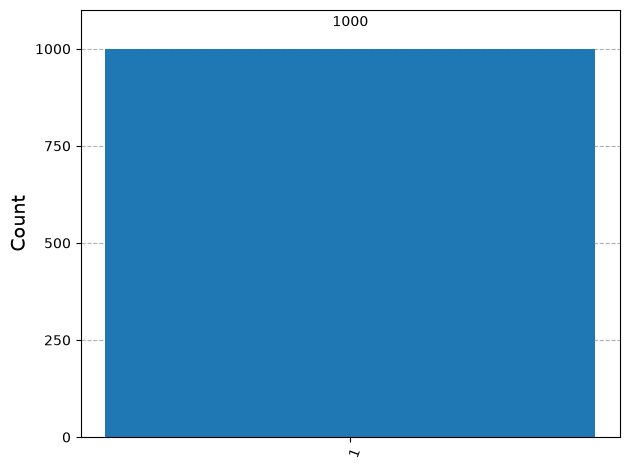

In [34]:
cuentas = estado.sample_counts(1000)

#Además hacemos un histograma con
plot_histogram(cuentas)

Para hacer un histograma de las probabilidades se hace:

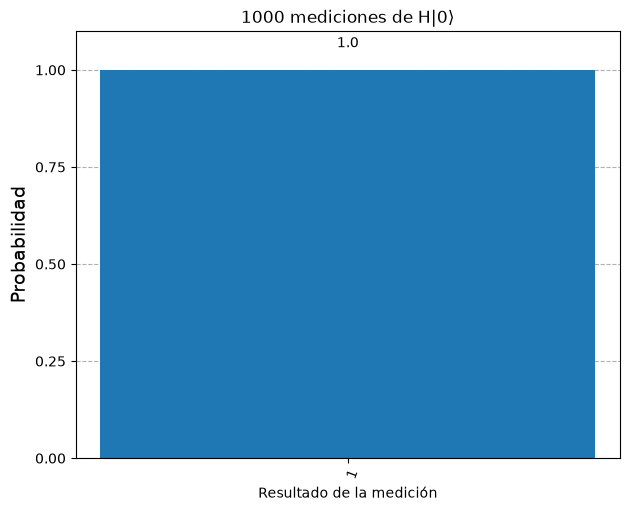

In [35]:
fig = plot_histogram(ProbDistribution(cuentas, shots=cuentas.shots()))
fig.axes[0].set_ylabel("Probabilidad")
fig.axes[0].set_xlabel("Resultado de la medición")
fig.axes[0].set_title("1000 mediciones de H|0⟩")

fig


Aproximadamente mitad y mitad. No sale exactamente 0.5 y 0.5, y eso no es un error sino simplemente fluctuación estadística. Si se aumenta el número de shots, las proporciones se acercan más al valor teórico.

Las probabilidades exactas se pueden obtener con la función `estado.probabilities_dict()`. Si se quiere graficar la probabilidad medida y la exacta se puede hacer:

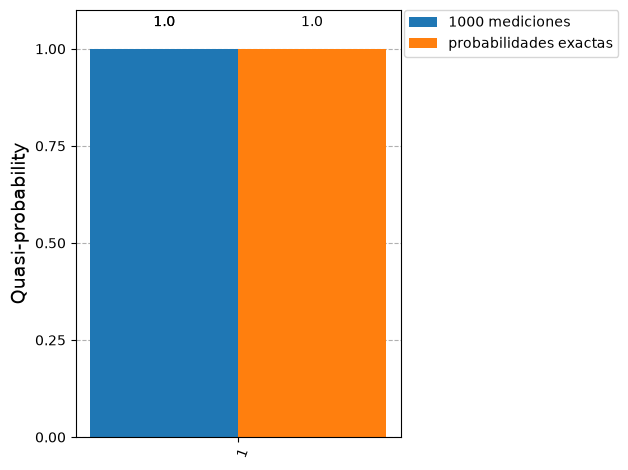

In [36]:
plot_histogram(
    [cuentas, estado.probabilities_dict()],
    legend=["1000 mediciones", "probabilidades exactas"],
)

### Ejercicio 4

Genera mil repeticiónes del experimento del circuito con la compuerta `X` del ejercicio 1 y
dibuja el histograma comparado con sus probabilidades exactas, igual que arriba.

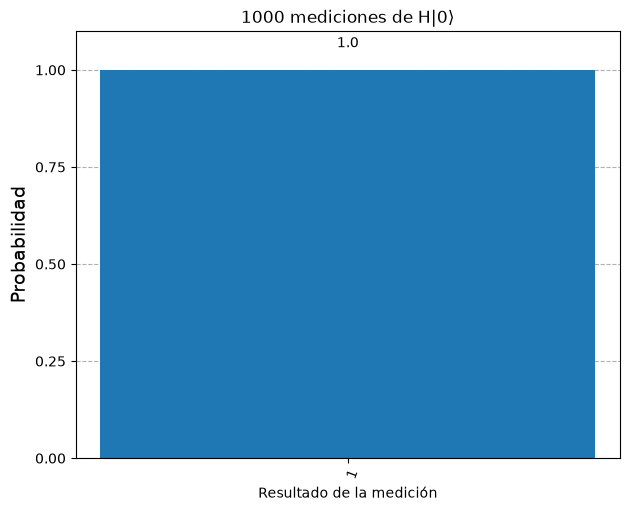

In [15]:
#Respuesta

qc = QuantumCircuit(1)
qc.x(0)
estado_x = Statevector(qc)

cuentas = estado_x.sample_counts(1000)

fig = plot_histogram(ProbDistribution(cuentas, shots=cuentas.shots()))
fig.axes[0].set_ylabel("Probabilidad")
fig.axes[0].set_xlabel("Resultado de la medición")
fig.axes[0].set_title("1000 mediciones de H|0⟩")
fig


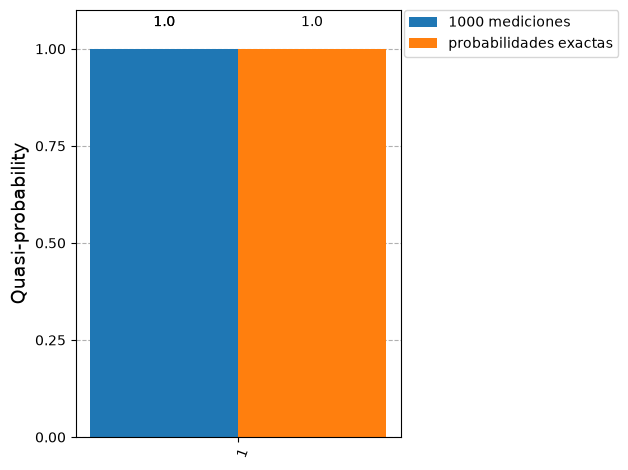

In [16]:
qc = QuantumCircuit(1)
qc.x(0)
estado_x = Statevector(qc)

cuentas_x = estado_x.sample_counts(1000)

plot_histogram(
    [cuentas_x, estado_x.probabilities_dict()],
    legend=["1000 mediciones", "probabilidades exactas"],
)

Se confirma visualmente que la compuerta $X$ invierte el qubit desde el Polo Norte ($\vert{}0\rangle$) hacia el Polo Sur ($\vert{}1\rangle$) de manera determinista, sin generar fluctuaciones estadísticas ni superposición. 

<details>
<summary>Ver respuesta</summary>

```python
cuentas_x = estado_x.sample_counts(1000)

plot_histogram(
    [cuentas_x, estado_x.probabilities_dict()],
    legend=["1000 mediciones", "probabilidades exactas"],
)
```

Una sola barra en `1`, con altura 1.0.

Aquí no hay fluctuación estadística. Las mil mediciones coinciden
exactamente con la probabilidad teórica, porque esa probabilidad es 1. Medir un
estado sin superposición no tiene nada de aleatorio.


</details>

#### <span style="color:blue">__¡Felicidades!__ </span>: El circuito cuántico "hola mundo" se considera que es la construcción del estado de superposición $\frac{1}{\sqrt{2}}\left(|0\rangle + |1\rangle \right)$ y su respectiva medición al momento de correr el circuito en distintos "shots".

## 5. Amplitudes complejas y la esfera de Bloch

Como se vió en la presentación, el estado más general de un qubit que resulta ser un punto en la esfera de Bloch definida por los ángulos $\theta$ (ángulo polar) y $\varphi$ (ángulo azimutal), se puede escribir como:
$$|\psi\rangle = \cos\frac{\theta}{2}\,|0\rangle + e^{i\varphi}\,\sin\frac{\theta}{2}\,|1\rangle .$$
En esta esfera polo norte es
$|0\rangle$ ($\theta = 0$), el polo sur es $|1\rangle$ ($\theta = \pi$)

Un ejemplo de un estado con números complejos es:

In [17]:
qc_i = QuantumCircuit(1)
qc_i.h(0)
estado_i = Statevector(qc_i)

psi = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])

print("|i>  amplitudes      :", estado_i.data)
print("¿es el mismo que psi?:", np.allclose(estado_i.data, psi.data))

|i>  amplitudes      : [0.70710678+0.j 0.70710678+0.j]
¿es el mismo que psi?: True


Para graficar un estado en la esfera de Bloch en qiskit se puede hacer:

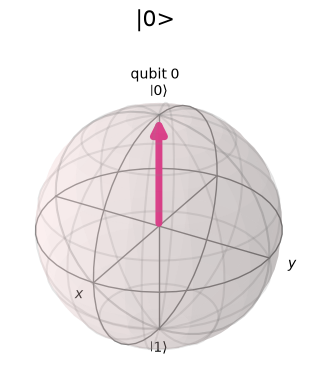

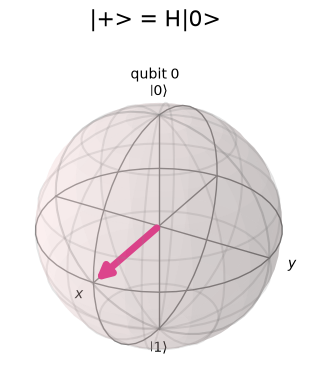

In [18]:
for nombre, est in [("|0>", Statevector([1, 0])), ("|+> = H|0>", estado_i)]:
    display(plot_bloch_multivector(est, title=nombre, figsize=(3.2, 3.2)))

### Ejercicio 5

La compuerta `Z` cambia el signo de la amplitud de $|1\rangle$ y se añade con `qc.z(0)`. Construye el
circuito `H` seguida de `Z`, obtén sus amplitudes, sus probabilidades y su representación en la esfera. 

In [19]:
#Respuesta
qc_hz = QuantumCircuit(1)
qc_hz.h(0) # Aplica h
qc_hz.z(0) # Aplica z despues de H

estado_hz = Statevector(qc_hz)

# un estado también se puede escribir a mano, dando sus dos amplitudes
psi = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])

print("Amplitudes     :", estado_hz.data)
print("Probabilidades :", estado_hz.probabilities())



Amplitudes     : [ 0.70710678+0.j -0.70710678+0.j]
Probabilidades : [0.5 0.5]


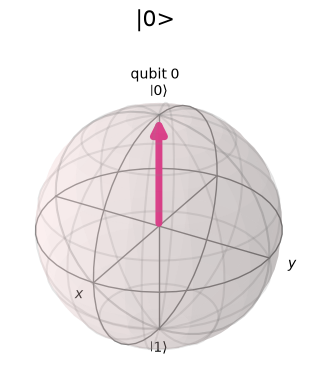

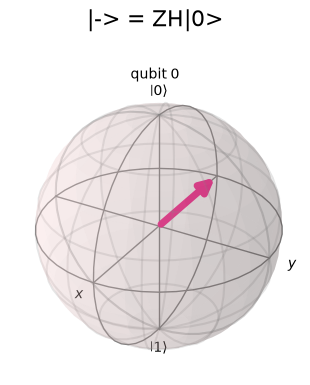

In [20]:
for nombre, est in [("|0>", Statevector([1, 0])), ("|-> = ZH|0>", estado_hz)]:
    display(plot_bloch_multivector(est, title=nombre, figsize=(3.2, 3.2)))

<details>
<summary>Ver respuesta</summary>

```python
qc_menos = QuantumCircuit(1)
qc_menos.h(0)
qc_menos.z(0)
estado_menos = Statevector(qc_menos)

print("amplitudes    :", estado_menos.data)
print("probabilidades:", estado_menos.probabilities())

plot_bloch_multivector(estado_menos, title="|-> = Z H|0>", figsize=(3.2, 3.2))
```

```
amplitudes    : [ 0.70710678+0.j -0.70710678+0.j]
probabilidades: [0.5 0.5]
```

Mismas probabilidades que $|+\rangle$, así que el mismo histograma. La diferencia es la fase
relativa, el signo menos y en la esfera se ve como la flecha apuntando al lado contrario del
eje $x$.

</details>

## Referencias

**Libros**

- M. A. Nielsen e I. L. Chuang, *Quantum Computation and Quantum Information*, edición del décimo aniversario, Cambridge University Press, 2010.
  - Sec. 1.2: el qubit, sus amplitudes y la medición. La esfera de Bloch es la ec. (1.4) y la fig. 1.3.
  - Sec. 1.3.1: compuertas de un qubit y la condición de unitariedad.
  - Sec. 2.2.7: fase global y fase relativa.
  - Sec. 4.2: la fig. 4.2 reúne las compuertas `H`, `X`, `Y`, `Z`, `S` y `T` con sus matrices.
- T. G. Wong, *Introduction to Classical and Quantum Computing*, Rooted Grove, 2022. Cap. 2 (superposición, medición, esfera de Bloch, compuertas y circuitos de un qubit) y sec. 3.3 (las compuertas como matrices y la unitariedad). [PDF gratuito del autor](https://www.thomaswong.net/introduction-to-classical-and-quantum-computing-1e4p.pdf).
- C. Bernhardt, *Quantum Computing for Everyone*, MIT Press, 2019. Caps. 1 a 3 (*Spin*, *Linear Algebra*, *Spin and Qubits*) y cap. 7 (*Quantum Gates and Circuits*). Trabaja sólo con números reales.
- A. Glassner, *Quantum Computing: From Concepts to Code*, No Starch Press, 2025. Caps. 2 (*Quantum States*), 3 (*Operators*), 4 (*Working with Qubits*) y 6 (*Measurement*).
- N. S. Yanofsky y M. A. Mannucci, *Quantum Computing for Computer Scientists*, Cambridge University Press, 2008. Secs. 4.1 (estados cuánticos), 4.3 (medición), 4.4 (evolución unitaria), 5.1 (bits y qubits) y 5.4 (compuertas cuánticas).

**Documentación de Qiskit**

- [`QuantumCircuit`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit): crear el circuito, los métodos `h`, `x`, `s` y `z`, y el dibujo con `draw`.
- [`Operator`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Operator): la matriz del circuito, en el atributo `data`.
- [`Statevector`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector): `probabilities`, `probabilities_dict`, `sample_counts` y `draw`.
- [`plot_histogram`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_histogram), [`plot_bloch_multivector`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_bloch_multivector) y [`ProbDistribution`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.result.ProbDistribution).
- [Biblioteca de compuertas](https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_library): cada compuerta estándar (`HGate`, `XGate`, `SGate`, `ZGate`, ...) tiene una página con su matriz.
- [Glosario de operaciones del Composer](https://quantum.cloud.ibm.com/docs/en/guides/composer), en la sección *Composer operations glossary*: una ficha por compuerta.
- J. Watrous, [*Basics of quantum information*](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information), IBM Quantum Learning, la plataforma que sustituyó al *Qiskit Textbook*. La lección que corresponde a este cuaderno es [*Single systems*](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/single-systems/introduction); su sección *Qiskit implementation* usa `Statevector`, `Operator`, `sample_counts` y `plot_histogram`.

## Licencia

Autores: Alejandro Contreras Reynoso, Adrian Ortega,  Universidad de Guadalajara,  2026

Este material se distribuye bajo una [Licencia Creative Commons
Atribución-NoComercial-SinDerivadas 4.0 Internacional (CC BY-NC-ND
4.0)](https://creativecommons.org/licenses/by-nc-nd/4.0/deed.es).

Se permite copiar y redistribuir el material en cualquier medio o formato, dando
crédito al autor. No se permite el uso comercial ni la distribución de versiones
modificadas.